In [1]:
#https://github.com/tamu-datathon-org/dashboard-royale/blob/main/GUIDE.md


In [2]:
!git clone --depth 1 https://github.com/tamu-datathon-org/dashboard-royale.git
!cd dashboard-royale

Cloning into 'dashboard-royale'...
remote: Enumerating objects: 88, done.
remote: Counting objects: 100% (88/88), done.
remote: Compressing objects: 100% (87/87), done.
remote: Total 88 (delta 1), reused 86 (delta 1), pack-reused 0 (from 0)
Receiving objects: 100% (88/88), 243.79 MiB | 28.51 MiB/s, done.
Resolving deltas: 100% (1/1), done.


In [3]:
import pandas as pd

# Pointing to the correct directory location within the cloned repository
daily = pd.read_parquet("dashboard-royale/data/1_prepared_views/prepared_daily_view.parquet")
print(daily.shape)   # (56110, 44): one row per machine per day
print(daily.head())

(56110, 44)
  machine_id gaming_date    month local_weekday  is_weekend federal_holiday  \
0     M-1001  2025-01-01  2025-01           Wed       False  New Year's Day   
1     M-1001  2025-01-02  2025-01           Thu       False            None   
2     M-1001  2025-01-03  2025-01           Fri       False            None   
3     M-1001  2025-01-04  2025-01           Sat        True            None   
4     M-1001  2025-01-05  2025-01           Sun        True            None   

  events_active zone_id      zone_name bank_id  ... zone_entries_observed  \
0          None   Z-ENT  Main Entrance    B-01  ...                1999.0   
1          None   Z-ENT  Main Entrance    B-01  ...                2530.0   
2          None   Z-ENT  Main Entrance    B-01  ...                3145.0   
3          None   Z-ENT  Main Entrance    B-01  ...                3560.0   
4          None   Z-ENT  Main Entrance    B-01  ...                2865.0   

  zone_counter_coverage_hours lease_cost_usd servi

In [4]:
for col in daily.columns:
    print(col)

machine_id
gaming_date
month
local_weekday
is_weekend
federal_holiday
events_active
zone_id
zone_name
bank_id
location_id
config_id
theme
configured_rtp
volatility_class
manufacturer
lease_class
active
meter_status
available_hours
occupied_hours
availability_ratio
occupancy_ratio
paid_spins
coin_in_usd
payout_usd
house_win_usd
theo_usd
observed_hold
theo_hold
luck_residual_usd
carded_coin_in_usd
carded_share
faults_opened
zone_entries_observed
zone_counter_coverage_hours
lease_cost_usd
service_cost_usd
power_cost_usd
repair_cost_usd
contribution_after_supplied_costs_usd
lag_coin_in_7d_mean_usd
lag_downtime_7d_hours
lag_house_win_28d_usd


In [5]:
daily.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 56110 entries, 0 to 56109
Data columns (total 44 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   machine_id                             56110 non-null  object 
 1   gaming_date                            56110 non-null  object 
 2   month                                  56110 non-null  object 
 3   local_weekday                          56110 non-null  object 
 4   is_weekend                             56110 non-null  bool   
 5   federal_holiday                        1550 non-null   object 
 6   events_active                          10230 non-null  object 
 7   zone_id                                55092 non-null  object 
 8   zone_name                              55092 non-null  object 
 9   bank_id                                55092 non-null  object 
 10  location_id                            55092 non-null  object 
 11  co

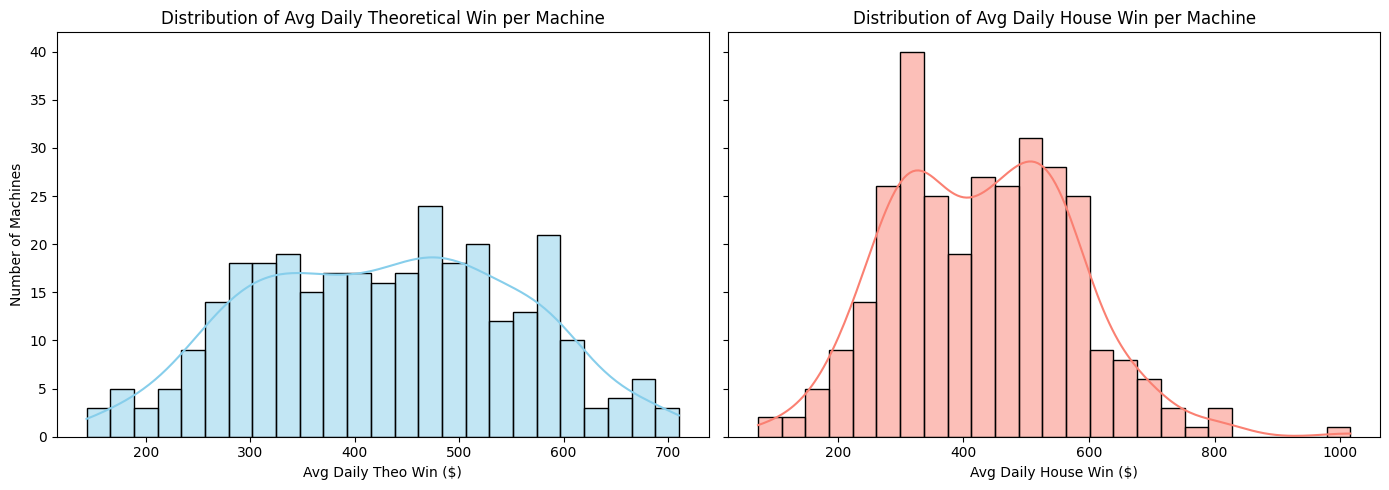

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load prepared daily view with correct repository path
df = pd.read_parquet("dashboard-royale/data/1_prepared_views/prepared_daily_view.parquet")

# 2. Filter to active days on the floor
active_df = df[df["active"]].copy()

# 3. Aggregate metrics by machine
machine_stats = active_df.groupby("machine_id").agg(
    total_house_win=("house_win_usd", "sum"),
    total_theo_win=("theo_usd", "sum"),
    active_days=("gaming_date", "count"),
    total_coin_in=("coin_in_usd", "sum")
).reset_index()

# Compute normalized daily metrics
machine_stats["daily_theo_win"] = machine_stats["total_theo_win"] / machine_stats["active_days"]
machine_stats["daily_house_win"] = machine_stats["total_house_win"] / machine_stats["active_days"]

# 4. Plot Histograms
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

# Distribution of Average Daily Theoretical Win
sns.histplot(machine_stats["daily_theo_win"], kde=True, ax=axes[0], color="skyblue", bins=25)
axes[0].set_title("Distribution of Avg Daily Theoretical Win per Machine")
axes[0].set_xlabel("Avg Daily Theo Win ($)")
axes[0].set_ylabel("Number of Machines")

# Distribution of Average Daily Actual House Win
sns.histplot(machine_stats["daily_house_win"], kde=True, ax=axes[1], color="salmon", bins=25)
axes[1].set_title("Distribution of Avg Daily House Win per Machine")
axes[1].set_xlabel("Avg Daily House Win ($)")

plt.tight_layout()
plt.show()

In [9]:
import pandas as pd

# 1. Load the prepared daily view
daily = pd.read_parquet("dashboard-royale/data/1_prepared_views/prepared_daily_view.parquet")

# 2. Filter for days the machine was active/available to account for exposure
active_daily = daily[daily['active'] == True]

# 3. Calculate average daily theo and house win per machine
machine_stats = active_daily.groupby('machine_id').agg(
    days_active=('gaming_date', 'count'),
    avg_daily_theo_usd=('theo_usd', 'mean'),
    avg_daily_house_win_usd=('house_win_usd', 'mean'),
    total_theo_usd=('theo_usd', 'sum'),
    total_house_win_usd=('house_win_usd', 'sum')
).reset_index()

# 4. Calculate the 'luck residual' (Actual Win - Expected Win)
# Negative variance means the machine was unlucky or players won more than expected.
machine_stats['daily_luck_variance'] = machine_stats['avg_daily_house_win_usd'] - machine_stats['avg_daily_theo_usd']

# 5. Sort to find the machines performing worst compared to their mathematical expectations
machine_stats = machine_stats.sort_values(by='avg_daily_house_win_usd')

# 6. Save to CSV for easy viewing or loading into a BI tool
machine_stats.to_csv("machine_performance_baseline.csv", index=False)

print(machine_stats.head(10))

    machine_id  days_active avg_daily_theo_usd avg_daily_house_win_usd  \
304     M-5076           49         152.626531               72.923469   
157     M-1158          181         287.077348               87.272099   
119     M-1120          132         143.264583              123.901515   
237     M-1238          181         183.090124                  137.75   
180     M-1181          181         179.647293              149.044199   
34      M-1035          181         170.688398              167.422652   
178     M-1179          181         186.655801              167.921271   
16      M-1017          181         163.125069              176.461326   
264     M-1265          181         177.949613              177.187845   
255     M-1256          181         267.986188              199.868785   

    total_theo_usd total_house_win_usd daily_luck_variance  
304      7478.7000             3573.25          -79.703061  
157     51961.0000            15796.25         -199.805249  
11

- Using theo_usd instead of house_win_usd removes luck. Theo calculates what the machine mathematically should have won based on how much it was played (coin-in) and its RTP. This prevents us from firing a good machine just because it paid out a few lucky jackpots.

- Dividing by available_hours removes downtime and install dates. This levels the playing field between a machine that has been running perfectly for 180 days and a machine that was installed in May or breaks down constantly.

These following are the bottom 10 sorted bu theo_per_hour


In [22]:
import pandas as pd

# 1. Load the prepared daily view
daily = pd.read_parquet("dashboard-royale/data/1_prepared_views/prepared_daily_view.parquet")

# 2. Filter out days the machine wasn't even on the floor (location_id is null or active is false)
floor_days = daily[(daily['active'] == True) & (daily['location_id'].notnull())]

# 3. Aggregate totals per machine
machine_performance = floor_days.groupby('machine_id').agg(
    days_on_floor=('gaming_date', 'count'),
    total_available_hours=('available_hours', 'sum'),
    total_coin_in=('coin_in_usd', 'sum'),
    total_theo=('theo_usd', 'sum'),
    total_house_win=('house_win_usd', 'sum')
).reset_index()

# 4. Filter out machines with negligible floor time (e.g., less than 7 days) to avoid skewed hourly rates
machine_performance = machine_performance[machine_performance['days_on_floor'] >= 7]

# Convert Decimal columns to float to allow division with float types
machine_performance['total_theo'] = machine_performance['total_theo'].astype(float)
machine_performance['total_coin_in'] = machine_performance['total_coin_in'].astype(float)

# 5. Calculate the true performance metric: Theo per Available Hour
machine_performance['theo_per_hour'] = machine_performance['total_theo'] / machine_performance['total_available_hours']
machine_performance['coin_in_per_hour'] = machine_performance['total_coin_in'] / machine_performance['total_available_hours']

# 6. Sort to find the 10 lowest earners by expected hourly win
true_bottom_10 = machine_performance.sort_values(by='theo_per_hour', ascending=True).head(10)

print(true_bottom_10[['machine_id', 'days_on_floor', 'total_available_hours', 'theo_per_hour', 'coin_in_per_hour']])

    machine_id  days_on_floor  total_available_hours  theo_per_hour  \
119     M-1120            132            3150.163611       6.003156   
304     M-5076             49            1170.000000       6.392051   
16      M-1017            181            4332.610833       6.814745   
34      M-1035            181            4339.386389       7.119578   
264     M-1265            181            4334.946389       7.430053   
180     M-1181            181            4333.617778       7.503237   
237     M-1238            181            4331.803611       7.650234   
178     M-1179            181            4325.226667       7.811082   
47      M-1048            181            4300.816389       8.530980   
161     M-1162            181            4327.096389       8.538751   

     coin_in_per_hour  
119        120.063129  
304        127.841026  
16         136.294898  
34         142.391561  
264         92.875658  
180         93.790459  
237        153.004686  
178         97.638525  
47

Compare to baseline (missuouri data)


In [13]:
import pandas as pd

benchmark_public = pd.read_parquet("/content/dashboard-royale/data/4_context/real_sources/benchmark_public.parquet")

benchmark_public.head(10)

,month,source_id,source_sheet,source_url,retrieved_date,source_sha256,property_id,property_name_as_reported,category,category_kind,slot_units,handle_usd,agr_usd,actual_payout_ratio,derived_hold_ratio,source_cells
0,2025-01,missouri_jan2025.xlsx,ARG,https://www.mgc.dps.mo.gov/Casino_Gaming/rb_fi...,2026-11-03,b9a72f59ecd223057e6e518f7cb3ebf9076478d570fcef...,argosy_riverside,ARGOSY RIVERSIDE,5 cents,game_category,104.0,12022415.35,708362.18,0.9410798779,0.0589201221,A44;D44;E44;F44;G44
1,2025-01,missouri_jan2025.xlsx,ARG,https://www.mgc.dps.mo.gov/Casino_Gaming/rb_fi...,2026-11-03,b9a72f59ecd223057e6e518f7cb3ebf9076478d570fcef...,argosy_riverside,ARGOSY RIVERSIDE,10 cents,game_category,8.0,5949826.11,446817.46,0.9249024338,0.0750975662,A45;D45;E45;F45;G45
2,2025-01,missouri_jan2025.xlsx,ARG,https://www.mgc.dps.mo.gov/Casino_Gaming/rb_fi...,2026-11-03,b9a72f59ecd223057e6e518f7cb3ebf9076478d570fcef...,argosy_riverside,ARGOSY RIVERSIDE,25 cents,game_category,59.0,3908181.00,281363.06,0.9280066455,0.0719933545,A46;D46;E46;F46;G46
3,2025-01,missouri_jan2025.xlsx,ARG,https://www.mgc.dps.mo.gov/Casino_Gaming/rb_fi...,2026-11-03,b9a72f59ecd223057e6e518f7cb3ebf9076478d570fcef...,argosy_riverside,ARGOSY RIVERSIDE,50 cents,game_category,1.0,1201818.50,83147.00,0.9308156764,0.0691843236,A47;D47;E47;F47;G47
4,2025-01,missouri_jan2025.xlsx,ARG,https://www.mgc.dps.mo.gov/Casino_Gaming/rb_fi...,2026-11-03,b9a72f59ecd223057e6e518f7cb3ebf9076478d570fcef...,argosy_riverside,ARGOSY RIVERSIDE,$1.00,game_category,113.0,13286982.08,949545.04,0.9285356875,0.0714643125,A48;D48;E48;F48;G48
5,2025-01,missouri_jan2025.xlsx,ARG,https://www.mgc.dps.mo.gov/Casino_Gaming/rb_fi...,2026-11-03,b9a72f59ecd223057e6e518f7cb3ebf9076478d570fcef...,argosy_riverside,ARGOSY RIVERSIDE,$2.00,game_category,9.0,2061196.00,107976.00,0.9476148799,0.0523851201,A49;D49;E49;F49;G49
6,2025-01,missouri_jan2025.xlsx,ARG,https://www.mgc.dps.mo.gov/Casino_Gaming/rb_fi...,2026-11-03,b9a72f59ecd223057e6e518f7cb3ebf9076478d570fcef...,argosy_riverside,ARGOSY RIVERSIDE,$5.00,game_category,17.0,1365388.29,148430.29,0.8912907844,0.1087092156,A50;D50;E50;F50;G50
7,2025-01,missouri_jan2025.xlsx,ARG,https://www.mgc.dps.mo.gov/Casino_Gaming/rb_fi...,2026-11-03,b9a72f59ecd223057e6e518f7cb3ebf9076478d570fcef...,argosy_riverside,ARGOSY RIVERSIDE,$25.00,game_category,2.0,164275.00,9255.00,0.9436615431,0.0563384569,A52;D52;E52;F52;G52
8,2025-01,missouri_jan2025.xlsx,ARG,https://www.mgc.dps.mo.gov/Casino_Gaming/rb_fi...,2026-11-03,b9a72f59ecd223057e6e518f7cb3ebf9076478d570fcef...,argosy_riverside,ARGOSY RIVERSIDE,1 cent,game_category,770.0,72681791.48,7660397.77,0.8946036192,0.1053963808,A54;D54;E54;F54;G54
9,2025-01,missouri_jan2025.xlsx,CARUTHERSVILLE,https://www.mgc.dps.mo.gov/Casino_Gaming/rb_fi...,2026-11-03,b9a72f59ecd223057e6e518f7cb3ebf9076478d570fcef...,century_caruthersville,CENTURY CARUTHERSVILLE,5 cents,game_category,12.0,351592.30,24413.05,0.9305643212,0.0694356788,A44;D44;E44;F44;G44


In [14]:
for col in benchmark_public.columns:
    print(col)

month
source_id
source_sheet
source_url
retrieved_date
source_sha256
property_id
property_name_as_reported
category
category_kind
slot_units
handle_usd
agr_usd
actual_payout_ratio
derived_hold_ratio
source_cells


Here is how the Missouri columns map to your casino data:

    handle_usd = Total Coin-in

    agr_usd (Adjusted Gross Revenue) = Total House Win

    slot_units = Number of available machines

In [19]:
import pandas as pd

# 1. Load the Missouri benchmark data
mo_data = pd.read_parquet("dashboard-royale/data/4_context/real_sources/benchmark_public.parquet")

# 2. Calculate the state-wide totals by first converting columns to float
total_agr = mo_data['agr_usd'].astype(float).sum()
total_machine_months = mo_data['slot_units'].astype(float).sum() # This represents 1 machine for 1 month

# 3. Calculate Win Per Unit Per Month, then Day, then Hour
# Assuming an average of 30.4 days in a month
avg_win_per_month = total_agr / total_machine_months
avg_win_per_day = avg_win_per_month / 30.4
avg_win_per_hour = avg_win_per_day / 24

print(f"Missouri State Average (WPUD): ${avg_win_per_day:.2f} per day")
print(f"Missouri State Average Hourly: ${avg_win_per_hour:.2f} per hour")

Missouri State Average (WPUD): $343.92 per day
Missouri State Average Hourly: $14.33 per hour


In [24]:
true_bottom = machine_performance.sort_values(by='theo_per_hour', ascending=True).head()

print(true_bottom[['machine_id', 'theo_per_hour']])

    machine_id  theo_per_hour
119     M-1120       6.003156
304     M-5076       6.392051
16      M-1017       6.814745
34      M-1035       7.119578
264     M-1265       7.430053
180     M-1181       7.503237
237     M-1238       7.650234
178     M-1179       7.811082
47      M-1048       8.530980
161     M-1162       8.538751
62      M-1063       8.713719
251     M-1252       9.242157
25      M-1026       9.336822
52      M-1053       9.569528
7       M-1008       9.609309
127     M-1128       9.662863
74      M-1075       9.857217
217     M-1218       9.870218
58      M-1059       9.927810
94      M-1095      10.327378
81      M-1082      10.407311
269     M-1270      10.599937
201     M-1202      10.609425
274     M-1275      10.622479
229     M-1230      10.727821


=== BENCHMARK SUMMARY ===
Missouri State Average Hourly Rate:      $14.33 / hr
The Gilded Ace Floor Average Hourly Rate: $17.88 / hr

=== TRULY WEAK BOTTOM 10 MACHINES ===
machine_id  active_days  total_available_hours  theo_per_hour  win_per_hour
    M-1120          132            3150.163611       6.003156      5.191794
    M-5076           49            1170.000000       6.392051      3.054060
    M-1017          181            4332.610833       6.814745      7.371883
    M-1035          181            4339.386389       7.119578      6.983361
    M-1265          181            4334.946389       7.430053      7.398246
    M-1181          181            4333.617778       7.503237      6.225053
    M-1238          181            4331.803611       7.650234      5.755743
    M-1179          181            4325.226667       7.811082      7.027088
    M-1048          181            4300.816389       8.530980      8.679922
    M-1162          181            4327.096389       8.538751      8

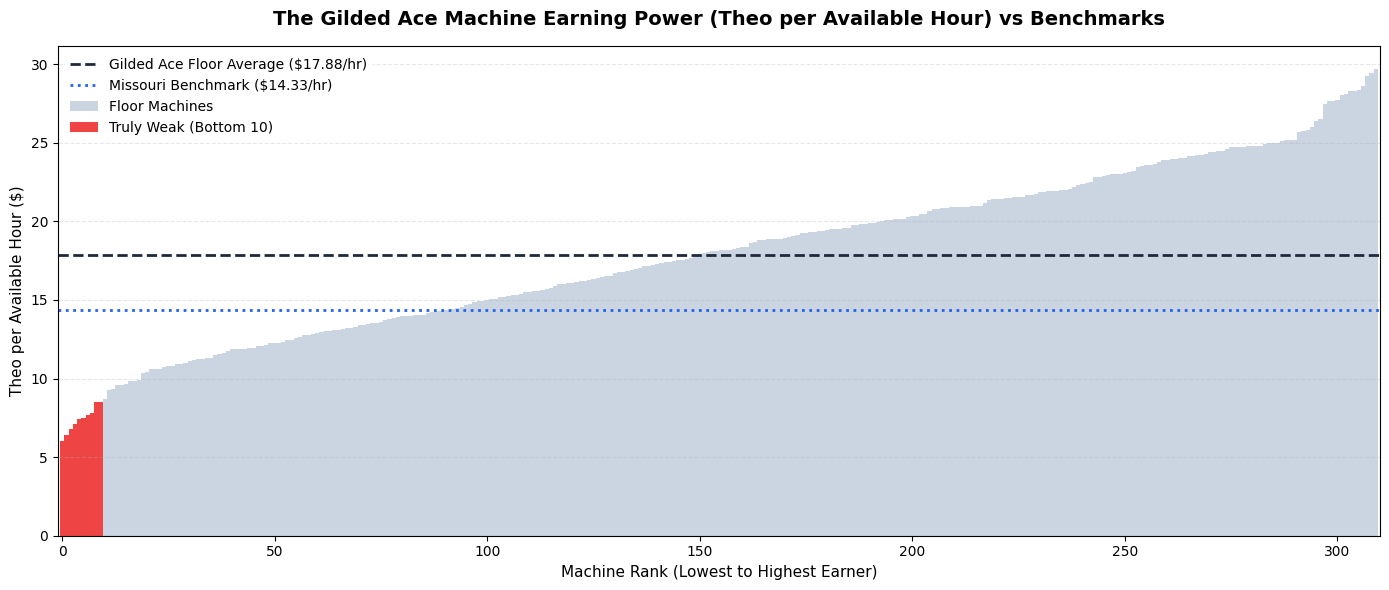

In [26]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


base_path = "dashboard-royale"

# 2. Load Parquet Data
daily = pd.read_parquet(f"{base_path}/data/1_prepared_views/prepared_daily_view.parquet")
mo_df = pd.read_parquet(f"{base_path}/data/4_context/real_sources/benchmark_public.parquet")
# Convert essential numerical columns to float explicitly to avoid type mismatches
daily['theo_usd'] = daily['theo_usd'].astype(float)
daily['house_win_usd'] = daily['house_win_usd'].astype(float)
daily['available_hours'] = daily['available_hours'].astype(float)

mo_df['agr_usd'] = mo_df['agr_usd'].astype(float)
mo_df['slot_units'] = mo_df['slot_units'].astype(float)

# 3. Calculate Missouri State Hourly Benchmark
total_mo_agr = mo_df['agr_usd'].sum()
total_mo_machine_hours = (mo_df['slot_units'] * 30.4 * 24.0).sum()
mo_hourly_benchmark = float(total_mo_agr / total_mo_machine_hours)

# 4. Filter for active floor days
active_days = daily[(daily['active'] == True) & (daily['location_id'].notnull())].copy()

# Group by machine to aggregate long-run totals
machine_stats = active_days.groupby('machine_id').agg(
    total_theo=('theo_usd', 'sum'),
    total_house_win=('house_win_usd', 'sum'),
    total_available_hours=('available_hours', 'sum'),
    active_days=('gaming_date', 'count')
).reset_index()

# Exclude machine deployments with fewer than 7 active floor days
machine_stats = machine_stats[machine_stats['active_days'] >= 7].copy()

# Enforce float precision on aggregated totals
machine_stats['total_theo'] = machine_stats['total_theo'].astype(float)
machine_stats['total_house_win'] = machine_stats['total_house_win'].astype(float)
machine_stats['total_available_hours'] = machine_stats['total_available_hours'].astype(float)

# Calculate Ratio of Sums rates
machine_stats['theo_per_hour'] = (machine_stats['total_theo'] / machine_stats['total_available_hours']).astype(float)
machine_stats['win_per_hour'] = (machine_stats['total_house_win'] / machine_stats['total_available_hours']).astype(float)

# Gilded Ace overall floor hourly benchmark
gilded_ace_floor_hourly = float(machine_stats['total_theo'].sum() / machine_stats['total_available_hours'].sum())

# Order machines ascending by theoretical earning power
machine_stats = machine_stats.sort_values(by='theo_per_hour', ascending=True).reset_index(drop=True)

# Extract Bottom 10 Truly Weak machines
bottom_10 = machine_stats.head(10).copy()

print("=== BENCHMARK SUMMARY ===")
print(f"Missouri State Average Hourly Rate:      ${mo_hourly_benchmark:.2f} / hr")
print(f"The Gilded Ace Floor Average Hourly Rate: ${gilded_ace_floor_hourly:.2f} / hr")
print("\n=== TRULY WEAK BOTTOM 10 MACHINES ===")
print(bottom_10[['machine_id', 'active_days', 'total_available_hours', 'theo_per_hour', 'win_per_hour']].to_string(index=False))

# 5. Visualizing Machine Earning Power vs Benchmarks
plt.figure(figsize=(14, 6), dpi=100)
x_ranks = np.arange(len(machine_stats))

plt.bar(x_ranks, machine_stats['theo_per_hour'], color='#cbd5e1', width=1.0, label='Floor Machines')
plt.bar(np.arange(10), bottom_10['theo_per_hour'], color='#ef4444', width=1.0, label='Truly Weak (Bottom 10)')

plt.axhline(gilded_ace_floor_hourly, color='#1e293b', linestyle='--', linewidth=2,
            label=f'Gilded Ace Floor Average (${gilded_ace_floor_hourly:.2f}/hr)')
plt.axhline(mo_hourly_benchmark, color='#2563eb', linestyle=':', linewidth=2,
            label=f'Missouri Benchmark (${mo_hourly_benchmark:.2f}/hr)')

plt.title('The Gilded Ace Machine Earning Power (Theo per Available Hour) vs Benchmarks', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Machine Rank (Lowest to Highest Earner)', fontsize=11)
plt.ylabel('Theo per Available Hour ($)', fontsize=11)
plt.xlim(-1, len(machine_stats))
plt.legend(frameon=True, facecolor='white', edgecolor='none')
plt.grid(axis='y', alpha=0.3, linestyle='--')
plt.tight_layout()
plt.show()

In [ ]:

here